# Number theory 7: The number field sieve

*Learning path: number theory, part 7 of 7.* [Index](README.md) · Previous: [The factoring lab](06-factoring-lab.ipynb)

Every record factorization since the 1990s, up to RSA-250 (250 digits, 2020), was done with the **number field
sieve**. Its cost grows like $L(1/3) = e^{1.92 (\ln N)^{1/3} (\ln \ln N)^{2/3}}$, while the quadratic sieve of the
last lessons grows like $L(1/2)$. This lesson builds the method up from one idea and runs Galileo's own (small,
plain) implementation on real numbers. You will see

* why a polynomial $f$ with $f(m) \equiv 0 \pmod N$ gives two worlds that agree modulo $N$,
* how pairs $(a, b)$ that are smooth in **both** worlds are found by a sieve,
* how linear algebra and a square root in a number field turn them into a factor,
* why numbers like $2^{128} + 1$ are much easier (the special number field sieve), and how the algebraic factoring of
  [lesson 3](03-algebraic-factoring.ipynb) can finish the job before any sieving starts,
* an honest race against the quadratic sieve.

## 1. One number, two worlds

The quadratic sieve looks for $x$ with $x^2 \bmod N$ small, so that it splits into small primes. Those numbers are
about $\sqrt N$, which is what makes it slow for large $N$. The number field sieve gets much smaller numbers by
working in two worlds at once.

Take a polynomial $f$ of degree $d$ and a whole number $m$ with $f(m) \equiv 0 \pmod N$. The simplest way: choose
$m \approx N^{1/d}$ and write $N$ in base $m$; the digits are the coefficients, so $f(m) = N$ exactly. Let $\alpha$
be a root of $f$ (a complex number). Numbers $a - b\alpha$ with whole $a, b$ can be added and multiplied like
polynomials in $\alpha$, and replacing $\alpha$ by $m$ keeps every product correct **modulo $N$**, because
$f(\alpha) = 0$ and $f(m) \equiv 0$. So if a set $S$ of pairs has

$$\prod_{S} (a - b m) = X^2 \quad\text{and}\quad \prod_{S} (a - b\alpha) = \beta^2,$$

then $X^2 \equiv \beta(m)^2 \pmod N$, and as in the quadratic sieve $\gcd(X - \beta(m), N)$ is a factor half of the
time.

For $N = 2^{128} + 1$ there is a much better polynomial than base $m$: $2 (2^{128} + 1) = (2^{43})^3 + 2$, so
$f(x) = x^3 + 2$ with $m = 2^{43}$. In the world of $\alpha = \sqrt[3]{-2}$, the size of $a - b\alpha$ is measured by
its **norm** $a^3 + 2 b^3$, a small number. Here is the pair $a = -100$, $b = 1$ in both worlds:

In [1]:
m = 2^43
a = -100; b = 1
factor(a - b*m)
factor(a^3 + 2*b^3)

8796093022208
1
-1 * 2^2 * 3 * 19 * 59 * 97 * 107 * 251^2
-1 * 2 * 31 * 127^2

Both sides break into primes below 300: the pair is **smooth on both sides**. The rational side is about $10^{13}$
and the algebraic side about $10^6$, while the quadratic sieve would be looking at numbers near $\sqrt N \approx 10^{19}$.
Smaller numbers are far more likely to be smooth, and that is the whole advantage.

## 2. The whole method on $2^{128} + 1$

`gnfs(N)` runs the number field sieve and prints each step. Without a polynomial it tries the special forms that the
algebraic factoring of lesson 3 recognizes ($N$ divides $b^k \pm 1$) and base-$m$ polynomials, and picks the one with
the best score.

In [2]:
gnfs(2^128 + 1)

The number field sieve split 340282366920938463463374607431768211457 = 5704689200685129054721 * 59649589127497217 in 1.7e6 work units (731 ms).

```
1. Polynomials considered (score = estimated bits of the two norms + alpha; lower is better):
      92.9  f(x) = x^3 + 2, m = 8796093022208  [special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43]
      96.9  f(x) = x^4 + 1, m = 4294967296  [special form: N divides 2^128 + 1, so f(x) = x^4 + 1 with m = 2^32]
      96.9  f(x) = x^4 + 1, m = 4294967296  [base m, degree 4]
     100.3  f(x) = x^2 + 1, m = 18446744073709551616  [special form: N divides 2^128 + 1, so f(x) = x^2 + 1 with m = 2^64]
     102.7  f(x) = x^5 + 4, m = 67108864  [special form: N divides 2^128 + 1, so f(x) = x^5 + 4 with m = 2^26]
1. f(x) = x^3 + 2, m = 8796093022208 (special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43): f(m) ≡ 0 mod N
    typical norms: rational about 10^15, algebraic about 10^12; Murphy alpha 1.73
2. Factor bases up to 2653: 383 rational primes, 371 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 106120
3. Sieved 521 lines b = 1..521 with |a| <= 24726 (25765013 pairs): 20328 candidates, 7633 relations (195 full, 7438 with large primes) [0.35 s]
4. After removing relations with a prime nobody else has: 1912 relations with 1865 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 459 x 438 (2 signs, 24 quadratic characters)
    linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.40 s]
5. Square roots: rational side from the exponents, algebraic side at q = 106453 where f splits
    dependency 1: 886 relations
    square root found 106453-adically to 1619 digits; its coefficients have about 1538 digits
    X ≡ ±Y: trivial, next dependency
    dependency 2: 868 relations
    square root found 106453-adically to 1584 digits; its coefficients have about 1499 digits
    X ≡ ±Y: trivial, next dependency
    dependency 3: 896 relations
    square root found 106453-adically to 1639 digits; its coefficients have about 1554 digits
    X ≡ ±Y: trivial, next dependency
    dependency 4: 930 relations
    square root found 106453-adically to 1694 digits; its coefficients have about 1608 digits
    X ≡ ±Y: trivial, next dependency
    dependency 5: 844 relations
    square root found 106453-adically to 1543 digits; its coefficients have about 1461 digits
    X ≡ ±Y: trivial, next dependency
    dependency 6: 850 relations
    square root found 106453-adically to 1548 digits; its coefficients have about 1467 digits
    X ≡ ±Y: trivial, next dependency
    dependency 7: 920 relations
    square root found 106453-adically to 1679 digits; its coefficients have about 1593 digits
    X ≡ ±Y: trivial, next dependency
    dependency 8: 882 relations
    square root found 106453-adically to 1614 digits; its coefficients have about 1529 digits
    X ≡ ±Y: trivial, next dependency
    dependency 9: 914 relations
    square root found 106453-adically to 1664 digits; its coefficients have about 1578 digits
    X ≡ ±Y: trivial, next dependency
    dependency 10: 944 relations
    square root found 106453-adically to 1719 digits; its coefficients have about 1636 digits
    X ≡ ±Y: trivial, next dependency
    dependency 11: 904 relations
    square root found 106453-adically to 1654 digits; its coefficients have about 1572 digits
6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 5704689200685129054721 [0.73 s]
```

How to read the report:

1. **Polynomial.** For $2^{128} + 1$ it picks $x^3 + 2$, $m = 2^{43}$ from the form $2^{128} + 1$.
2. **Factor bases.** On the rational side, the primes $p$ up to a bound $B$. On the algebraic side, the pairs
   $(p, r)$ with $f(r) \equiv 0 \pmod p$: the prime $p$ divides the norm of $a - b\alpha$ exactly when
   $a \equiv b r \pmod p$. (These pairs are the prime ideals of degree one; the norm alone cannot tell which root,
   and it matters.)
3. **Sieve.** For each line $b = 1, 2, \ldots$ and $|a| \le A$, add $\log p$ at every $a \equiv b m \pmod p$ on the
   rational side and every $a \equiv b r \pmod p$ on the algebraic side, exactly like the sieve of Eratosthenes.
   Where both totals come close to the size of the number, check by division. One leftover **large prime** per side
   is allowed; it is useful only if another relation has the same one.
4. **Linear algebra.** Each relation is a vector of exponents mod 2 (plus the signs). Relations that share a rare
   prime are added together first, which shrinks the matrix, then Gaussian elimination finds sets whose exponents
   are all even. Even exponents on the algebraic side are not quite enough for a square in $\mathbb{Z}[\alpha]$
   (units and the class group get in the way), so there are 24 more columns: **quadratic characters**, the
   Legendre symbols $\left(\frac{a - b s}{q}\right)$ for primes $q$ outside the factor base. A real square gives $+1$
   for every one of them. Characters make a square very likely, not certain; if a set still is not a square, the
   square root step notices and moves on to the next set.
5. **Square roots.** The rational one comes from halving the exponents. The algebraic one, $\beta$ with
   $\beta^2 = f'(\alpha)^2 \prod (a - b\alpha)$, is the hard part of the method: Galileo takes a prime $q$ where $f$
   has $d$ roots, takes square roots of the product at each root modulo $q$, lifts them to modulo $q^{k}$ (Hensel's
   lemma, Newton's method for $p$-adic numbers) until $q^k$ is larger than the coefficients of $\beta$, and
   interpolates. The coefficients have thousands of digits, but they are exact. (The factor $f'(\alpha)^2$
   guarantees that $\beta$ has whole-number coefficients.)
6. **gcd.** $X = f'(m) \prod \sqrt{a - b m}$ and $Y = \beta(m)$ satisfy $X^2 \equiv Y^2 \pmod N$. If $X \equiv \pm Y$
   the set was unlucky and the next one is tried.

## 3. When the polynomial factors

Some special forms give a polynomial that is not irreducible. Then the number field sieve has nothing to do: if
$f = g h$ then $f(m) = g(m) h(m)$, and $\gcd(g(m), N)$ often is a factor already. This is exactly the algebraic
factoring of lesson 3. Sophie Germain's identity $x^4 + 4 = (x^2 + 2x + 2)(x^2 - 2x + 2)$ with $x = 2^{20}$ gives
$2^{80} + 4 = 4 (2^{78} + 1)$:

In [3]:
gnfs(2^78 + 1, x^4 + 4, 2^20)

The number field sieve split 302231454903657293676545 = 549754765313 * 549756862465 in 0 work units (<1 ms).

```
1. f(x) = x^4 + 4, m = 1048576 (your polynomial): f(m) ≡ 0 mod N
    f factors over the integers: (x^2 - 2*x + 2) (x^2 + 2*x + 2)
    gcd(g(m), N) = 549754765313 for the factor g = x^2 - 2*x + 2: done without sieving
```

`gnfs(N, f, m)` uses your polynomial; $f(m)$ must be divisible by $N$. That is how one special form can give a
cheap algebraic split while the same idea with an irreducible $f$ powers the sieve.

## 4. Choosing the polynomial

The time of the sieve depends mostly on how large the two norms are. `nfspoly(N)` lists polynomials with a
**score**: the estimated number of bits of both norms over a typical sieve region, plus Murphy's $\alpha$, which
rewards polynomials that have many roots modulo small primes (their values are divisible by small primes more often
than random numbers). Lower is better.

In [4]:
nfspoly(2^128 + 1)

| score | norm bits | alpha | f(x) | m | how |
|---|---|---|---|---|---|
| 92.9 | 91.2 | 1.73 | $x^3 + 2$ | 8796093022208 | special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43 |
| 96.9 | 93.6 | 3.32 | $x^4 + 1$ | 4294967296 | special form: N divides 2^128 + 1, so f(x) = x^4 + 1 with m = 2^32 |
| 96.9 | 93.6 | 3.32 | $x^4 + 1$ | 4294967296 | base m, degree 4 |
| 100.3 | 98.7 | 1.56 | $x^2 + 1$ | 18446744073709551616 | special form: N divides 2^128 + 1, so f(x) = x^2 + 1 with m = 2^64 |
| 102.7 | 101.1 | 1.62 | $x^5 + 4$ | 67108864 | special form: N divides 2^128 + 1, so f(x) = x^5 + 4 with m = 2^26 |
| 113.2 | 110.5 | 2.64 | $x^6 + 16$ | 4194304 | special form: N divides 2^128 + 1, so f(x) = x^6 + 16 with m = 2^22 |
| 119.7 | 119.1 | 0.60 | $x^3 + 6285202991*x^2 + 805709614380*x + 2208031117835$ | 6979369219251 | base m, degree 3 |

score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster

The degree is a balance. A higher degree makes $m = N^{1/d}$ and so the rational norm smaller, but the algebraic
norm grows like $A^d$. Try two of them on the same number:

In [5]:
gnfs(2^128 + 1, x^4 + 1, 2^32)

The number field sieve split 340282366920938463463374607431768211457 = 5704689200685129054721 * 59649589127497217 in 2.2e6 work units (778 ms).

```
1. f(x) = x^4 + 1, m = 4294967296 (your polynomial): f(m) ≡ 0 mod N
    typical norms: rational about 10^12, algebraic about 10^16; Murphy alpha 3.32
2. Factor bases up to 3451: 482 rational primes, 465 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 138040
3. Sieved 482 lines b = 1..482 with |a| <= 28427 (27404110 pairs): 26630 candidates, 9209 relations (299 full, 8910 with large primes) [0.49 s]
4. After removing relations with a prime nobody else has: 2287 relations with 2222 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 510 x 478 (2 signs, 24 quadratic characters)
    linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.54 s]
5. Square roots: rational side from the exponents, algebraic side at q = 138433 where f splits
    dependency 1: 960 relations
    no square root with whole coefficients: the product is not a square in Z[α] after all (the characters only make that likely), next dependency
    dependency 2: 1032 relations
    square root found 138433-adically to 1666 digits; its coefficients have about 1547 digits
    X ≡ ±Y: trivial, next dependency
    dependency 3: 1008 relations
    square root found 138433-adically to 1625 digits; its coefficients have about 1504 digits
6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 5704689200685129054721 [0.78 s]
```

For a number without a special form, only the base-$m$ polynomials remain, and their coefficients are as large as
$m$:

In [6]:
N = semiprime(40, 1)
nfspoly(N)

4754405852378758586278577751857000165449

| score | norm bits | alpha | f(x) | m | how |
|---|---|---|---|---|---|
| 113.2 | 112.3 | 0.91 | $x^4 + 8722300*x^3 + 456931343*x^2 - 927222639*x + 1529376589$ | 8301566412 | base m, degree 4 |
| 118.1 | 118.7 | -0.63 | $x^3 + 1891766625*x^2 - 276048960581*x + 1419330539245$ | 16814442184548 | base m, degree 3 |

score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster

Compare the scores with the special form above: about 113 bits against 93 for $2^{128} + 1$, which has about the
same size. Twenty bits more in the norms means far fewer smooth pairs. That is why the special number field sieve
reaches numbers about 1.5 times as long as the general one with the same work. Serious programs spend hours
searching for good polynomials (Kleinjung's method, root sieving); `nfspoly` only tries a few values of $m$.

## 5. General numbers and the race against the quadratic sieve

Here is the general number field sieve on a 30-digit semiprime:

In [7]:
gnfs(semiprime(30, 1))

The number field sieve split 571777213143965220843759947161 = 746427731226967 * 766018181296783 in 2.1e6 work units (759 ms).

```
1. Polynomials considered (score = estimated bits of the two norms + alpha; lower is better):
      94.9  f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209  [base m, degree 4]
     100.0  f(x) = x^3 + 7160742*x^2 + 987349042*x + 673677296, m = 8297566417  [base m, degree 3]
1. f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209 (base m, degree 4): f(m) ≡ 0 mod N
    typical norms: rational about 10^10, algebraic about 10^19; Murphy alpha -1.48
2. Factor bases up to 4620: 623 rational primes, 595 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 184800
3. Sieved 163 lines b = 1..163 with |a| <= 30000 (9780163 pairs): 24201 candidates, 10291 relations (483 full, 9808 with large primes) [0.52 s]
4. After removing relations with a prime nobody else has: 2228 relations with 2164 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 497 x 465 (2 signs, 24 quadratic characters)
    linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.57 s]
5. Square roots: rational side from the exponents, algebraic side at q = 185167 where f splits
    dependency 1: 952 relations
    square root found 185167-adically to 4109 digits; its coefficients have about 2717 digits
6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 746427731226967 [0.76 s]
```

And the scoreboard of lesson 6, with `"nfs"` as a method:

**Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 0), at most 30.00 s per run.

| method | digits | solved | median work | median time |
|---|---|---|---|---|
| `qs` | 20 | 1/1 | 3.5e4 | 52 ms |
| `qs` | 24 | 1/1 | 5.6e4 | 53 ms |
| `qs` | 28 | 1/1 | 5.3e4 | 62 ms |
| `qs` | 32 | 1/1 | 1.7e5 | 85 ms |
| `nfs` | 20 | 1/1 | 1.5e5 | 142 ms |
| `nfs` | 24 | 1/1 | 3.5e5 | 204 ms |
| `nfs` | 28 | 1/1 | 1.3e6 | 552 ms |
| `nfs` | 32 | 1/1 | 5.8e6 | 2.31 s |

**How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):

- `qs`: cost grows like N^0.018 (fit on 4 sizes); L(1/2) constant 0.11, L(1/3) constant 0.21; best fit: N^a (few sizes: the models are hard to tell apart)
- `nfs`: cost grows like N^0.102 (fit on 4 sizes); L(1/2) constant 0.62, L(1/3) constant 1.20; best fit: N^a (few sizes: the models are hard to tell apart)


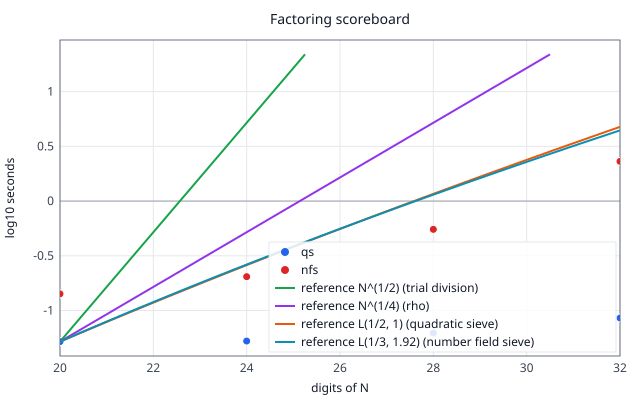

In [8]:
sb = scoreboard(["qs" "nfs"], 20:4:32, 1, 30)
scoreplot(sb)

The quadratic sieve wins at these sizes, by a factor of about 30. That is not a flaw of the lesson: also in serious
implementations the number field sieve only overtakes the quadratic sieve at around 100 digits, because its steps
(two factor bases, characters, the algebraic square root) cost more and its advantage, the $1/3$ in the exponent,
grows slowly. With this code on a normal computer:

* the 51-digit part of $2^{193} - 1$ (special form, polynomial $x^4 - 8$): about 7 s, quadratic sieve about 2 s,
* the Fermat number $2^{256} + 1$ (78 digits, special form $x^5 + 16$, $m = 2^{52}$): the special number field
  sieve splits it as $1238926361552897 \times p_{62}$ in under 3 minutes, while the quadratic sieve of lesson 6 does
  not finish in 5 minutes.

Larger numbers need what real programs (CADO-NFS, msieve) add: lattice sieving instead of line sieving, two or three
large primes per side, block Lanczos or block Wiedemann for matrices with millions of rows, and good polynomials. With
those, RSA-250 took about 2700 core-years.

## Summary

* Two worlds: $\mathbb{Z}$ and $\mathbb{Z}[\alpha]$ with $f(\alpha) = 0$, joined by $\alpha \mapsto m$ modulo $N$.
* A relation is a pair $(a, b)$ with $a - bm$ and the norm $b^d f(a/b)$ both smooth; a sieve finds them.
* Linear algebra mod 2, with signs and quadratic characters, picks a square on both sides; the algebraic square root
  is computed $q$-adically.
* Special forms give tiny polynomials (SNFS); forms whose polynomial factors are split by algebra alone.
* `gnfs(N)`, `gnfs(N, f, m)`, `nfspoly(N)`, and the method `"nfs"` in `labrun` and `scoreboard`.

**Try it:** run `gnfs(2^128 + 1, x^5 + 4, 2^26)` (degree 5) and compare the work with degree 3 and 4. Run
`gnfs(10^40 + 1, x^5 + 1, 10^8)` and explain what happens (what is $x^5 + 1$ over the integers?). Compare
`labrun("nfs", 2^128 + 1)` with `labrun("ecm", 2^128 + 1)`: why does ECM win here, where one factor has only 17
digits?

## Sources

1. A. K. Lenstra and H. W. Lenstra (eds.), *The Development of the Number Field Sieve*, Lecture Notes in Math. 1554, Springer (1993).
2. J. P. Buhler, H. W. Lenstra and C. Pomerance, "Factoring integers with the number field sieve", in [1], 50–94.
3. C. Pomerance, "A tale of two sieves", *Notices of the AMS* 43 (1996) 1473–1485.
4. A. K. Lenstra, H. W. Lenstra, M. S. Manasse and J. M. Pollard, "The factorization of the ninth Fermat number", *Math. Comp.* 61 (1993) 319–349.
5. R. P. Brent and J. M. Pollard, "Factorization of the eighth Fermat number", *Math. Comp.* 36 (1981) 627–630.
6. M. E. Briggs, *An Introduction to the General Number Field Sieve*, master's thesis, Virginia Tech (1998).
7. B. A. Murphy, *Polynomial Selection for the Number Field Sieve Integer Factorisation Algorithm*, PhD thesis, Australian National University (1999).
8. P. L. Montgomery, "Square roots of products of algebraic numbers", *Proc. Symp. Applied Math.* 48 (1994) 567–571; J.-M. Couveignes, "Computing a square root for the number field sieve", in [1], 95–102.
9. F. Boudot, P. Gaudry, A. Guillevic, N. Heninger, E. Thomé and P. Zimmermann, "Comparing the difficulty of factorization and discrete logarithm: a 240-digit experiment", *CRYPTO 2020*; the RSA-250 announcement (2020).
10. R. Crandall and C. Pomerance, *Prime Numbers: A Computational Perspective*, 2nd ed., Springer (2005), section 6.2.